In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore, pearsonr
from config import PREPROCESSED, FIGURES, print_versions
print_versions()

P05 = str(PREPROCESSED)
FIG = str(FIGURES)
FS = 125

train_parts = range(9)
val_parts   = range(9, 12)
test_parts  = range(12, 15)
lags = np.arange(-20, 50)          # -160 to 392 ms
ridge_parameter = 1e3

ch_names = open(os.path.join(P05, "ch_names.txt")).read().split()

eegs, stims = [], []
for i in range(15):
    e = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
    s = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))
    n = min(e.shape[1], len(s))
    eegs.append(zscore(e[:, :n], axis=1))
    stims.append(zscore(s[:n]))

def lag_chapter(s, eeg, lags):
    """Lagged feature and matching EEG for one chapter, edge samples discarded."""
    n = len(s)
    t0, t1 = lags.max(), n + lags.min()          # samples with every lag available
    X = np.vstack([s[t0 - L : t1 - L] for L in lags])
    return X, eeg[:, t0:t1]

def design(parts):
    Xs, Ys = zip(*(lag_chapter(stims[i], eegs[i], lags) for i in parts))
    return np.hstack(Xs), np.hstack(Ys)

X_train, train_eeg = design(train_parts)
X_val,   val_eeg   = design(val_parts)
X_test,  test_eeg  = design(test_parts)

coef = np.linalg.solve(X_train @ X_train.T
                       + ridge_parameter * np.eye(X_train.shape[0]),
                       X_train @ train_eeg.T)

predicted_eeg = X_test.T @ coef

r = np.array([pearsonr(predicted_eeg[:, i], test_eeg[i])[0] for i in range(63)])
print(f"test  mean r {r.mean():.4f}   max r {r.max():.4f}   best {ch_names[r.argmax()]}")
for c in np.argsort(r)[::-1][:5]:
    print(f"  {ch_names[c]:>5}  {r[c]:.4f}")

Python 3.12.13 | numpy 2.5.3 | scipy 1.18.1 | sklearn 1.9.0 | mne 1.12.1 | h5py 3.16.0 | matplotlib 3.11.1
test  mean r 0.0364   max r 0.0898   best FC5
    FC5  0.0898
    FC3  0.0647
   FT10  0.0639
    FC6  0.0582
    PO3  0.0555


best alpha 1.0e+12   val mean r 0.0327
test mean r 0.0410   max r 0.0898   best FC5
alpha 1e3    val mean r 0.0265


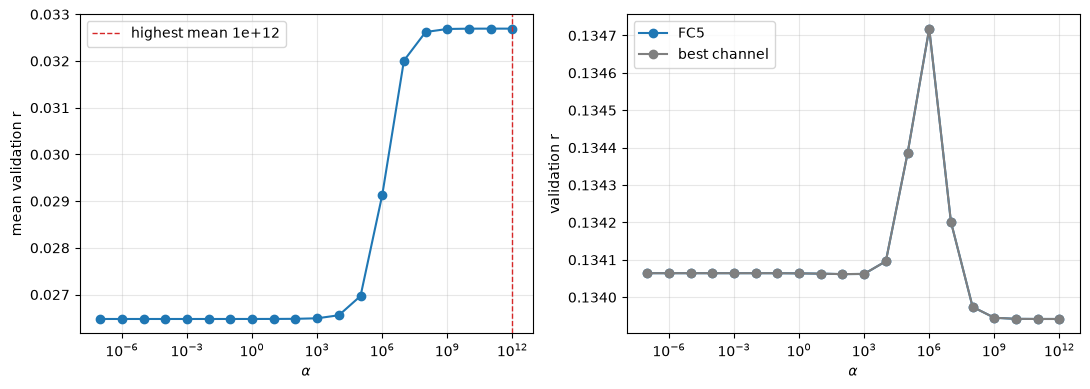

In [2]:
# Ridge sweep for the forward model.
# Reuses eegs, stims, lags, design, train_parts, val_parts from cell 0.
alphas = np.logspace(-7, 12, 20)         # extends the backward-model grid to 1e12


XtX = X_train @ X_train.T
Xty = X_train @ train_eeg.T
I   = np.eye(X_train.shape[0])

def channel_r(coef, X, eeg):
    pred = X.T @ coef
    return np.array([pearsonr(pred[:, i], eeg[i])[0] for i in range(eeg.shape[0])])

coefs    = {a: np.linalg.solve(XtX + a * I, Xty) for a in alphas}
val_r    = {a: channel_r(coefs[a], X_val, val_eeg) for a in alphas}
val_mean = {a: val_r[a].mean() for a in alphas}

best = max(val_mean, key=val_mean.get)
test_r = channel_r(coefs[best], X_test, test_eeg)
print(f"best alpha {best:.1e}   val mean r {val_mean[best]:.4f}")
print(f"test mean r {test_r.mean():.4f}   max r {test_r.max():.4f}   best {ch_names[test_r.argmax()]}")

# Is the choice well identified? Compare against the fixed value used previously.
print(f"alpha 1e3    val mean r {val_mean[1e3]:.4f}" if 1e3 in val_mean else
      f"alpha nearest 1e3  val mean r {val_mean[min(alphas, key=lambda a: abs(np.log10(a) - 3))]:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].semilogx(alphas, [val_mean[a] for a in alphas], 'o-')
axs[0].axvline(best, c='tab:red', ls='--', lw=1, label=f'highest mean {best:.0e}')
axs[0].set_xlabel(r'$\alpha$'); axs[0].set_ylabel('mean validation r')
axs[0].legend(); axs[0].grid(True, alpha=0.3)

c = ch_names.index('FC5')
axs[1].semilogx(alphas, [val_r[a][c] for a in alphas], 'o-', c='tab:blue', label='FC5')
axs[1].semilogx(alphas, [val_r[a].max() for a in alphas], 'o-', c='tab:grey', label='best channel')
axs[1].set_xlabel(r'$\alpha$'); axs[1].set_ylabel('validation r')
axs[1].legend(); axs[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "env_fwd_alpha.pdf"), bbox_inches="tight")

In [3]:
# Which channels drive the rise in mean validation r between alpha = 1e3 and 1e12?
d = val_r[alphas[-1]] - val_r[1e3]                 # change in validation r per channel
weak = val_r[1e3] < np.median(val_r[1e3])          # weaker half of channels at alpha = 1e3
print(f"mean change   weaker half {d[weak].mean():.4f}   stronger half {d[~weak].mean():.4f}   "
      f"share of total rise from weaker half {d[weak].sum() / d.sum():.0%}")

mean change   weaker half 0.0079   stronger half 0.0046   share of total rise from weaker half 62%


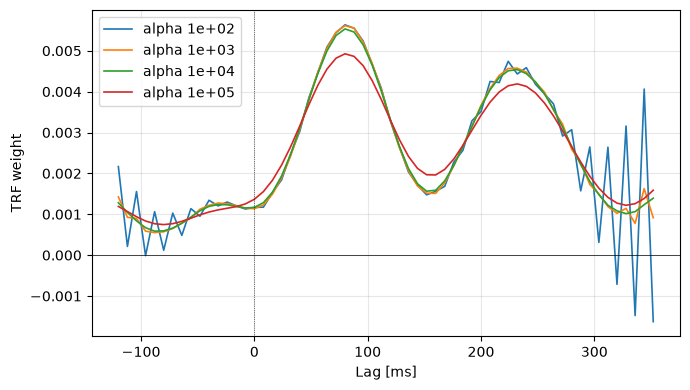

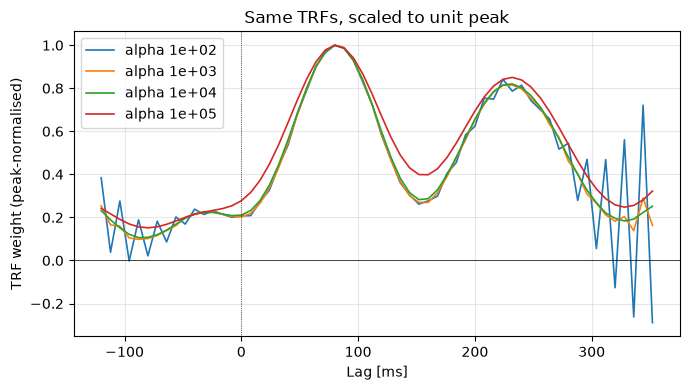

In [4]:
# FC5 TRF across regularisation strengths
c = ch_names.index('FC5')
picks = [min(alphas, key=lambda a: abs(np.log10(a) - e)) for e in [2, 3, 4, 5]]
t_ms = lags / FS * 1000
keep = slice(5, len(lags) - 5)        # drop the unstable end lags
plt.figure(figsize=(7, 4))
for a in picks:
    plt.plot(t_ms[keep], coefs[a][keep, c], lw=1.2, label=f'alpha {a:.0e}')
plt.axhline(0, c='k', lw=0.5)
plt.axvline(0, c='k', lw=0.5, ls=':')
plt.xlabel('Lag [ms]'); plt.ylabel('TRF weight')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "env_fwd_trf_alpha.pdf"), bbox_inches="tight")

plt.figure(figsize=(7, 4))
for a in picks:
    w = coefs[a][keep, c]
    plt.plot(t_ms[keep], w / np.abs(w).max(), lw=1.2, label=f'alpha {a:.0e}')
plt.axhline(0, c='k', lw=0.5)
plt.axvline(0, c='k', lw=0.5, ls=':')
plt.xlabel('Lag [ms]'); plt.ylabel('TRF weight (peak-normalised)')
plt.title('Same TRFs, scaled to unit peak')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()

FC5 peak    -32 ms   weight 0.0013
FC5 peak     80 ms   weight 0.0056
FC5 peak    232 ms   weight 0.0046
FC5 peak    328 ms   weight 0.0011
FC5 peak    344 ms   weight 0.0016
FC5 trough  -88 ms   weight 0.0006
FC5 trough    0 ms   weight 0.0011
FC5 trough  160 ms   weight 0.0015
FC5 trough  320 ms   weight 0.0010
FC5 trough  336 ms   weight 0.0008
FC5 mean weight at negative lags 0.0010
FC5 negative lags: min 0.0006   max 0.0014


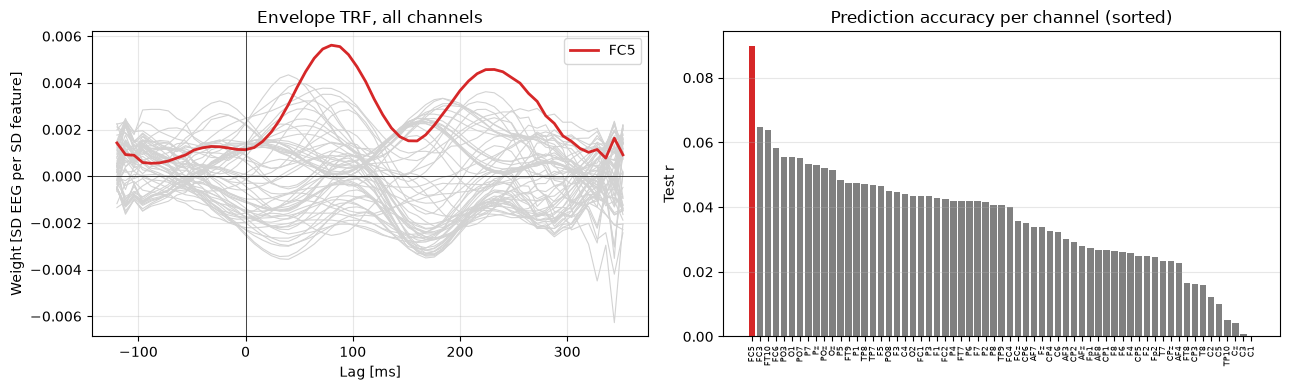

In [5]:
t_ms = lags / FS * 1000
keep = slice(5, len(lags) - 5)      # drop the unstable end lags
c = ch_names.index('FC5')

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

axs[0].plot(t_ms[keep], coef[keep, :], c='lightgrey', lw=0.8)
axs[0].plot(t_ms[keep], coef[keep, c], c='tab:red', lw=2, label='FC5')
axs[0].axhline(0, c='k', lw=0.5); axs[0].axvline(0, c='k', lw=0.5)
axs[0].set_xlabel('Lag [ms]'); axs[0].set_ylabel('Weight [SD EEG per SD feature]')
axs[0].set_title('Envelope TRF, all channels'); axs[0].legend()
axs[0].grid(True, alpha=0.3)

order = np.argsort(r)[::-1]
axs[1].bar(range(63), r[order], color=['tab:red' if k == c else 'grey' for k in order])
axs[1].set_xticks(range(63))
axs[1].set_xticklabels([ch_names[i] for i in order], rotation=90, fontsize=6)
axs[1].set_ylabel('Test r'); axs[1].set_title('Prediction accuracy per channel (sorted)')
axs[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG, "env_trf.pdf"), bbox_inches="tight")

from scipy.signal import find_peaks
w, tk = coef[keep, c], t_ms[keep]
for p in find_peaks(w)[0]:  print(f"FC5 peak   {tk[p]:4.0f} ms   weight {w[p]:.4f}")
for p in find_peaks(-w)[0]: print(f"FC5 trough {tk[p]:4.0f} ms   weight {w[p]:.4f}")
print(f"FC5 mean weight at negative lags {w[tk < 0].mean():.4f}")
print(f"FC5 negative lags: min {w[tk < 0].min():.4f}   max {w[tk < 0].max():.4f}")

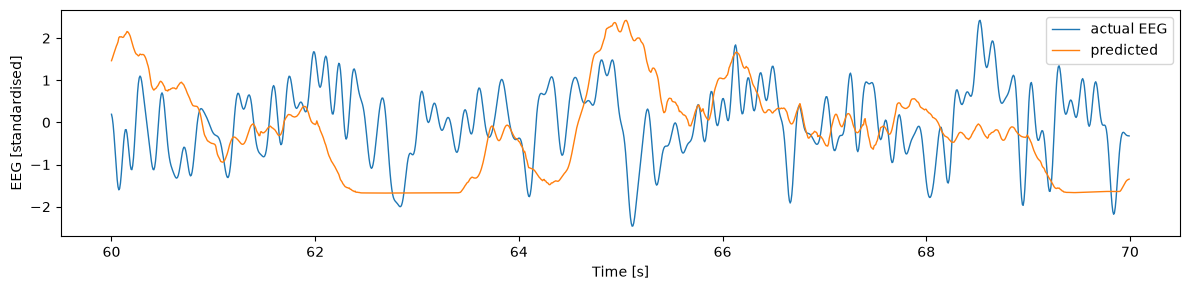

In [6]:
seg = slice(60 * FS, 70 * FS)
tt = np.arange(len(test_eeg[c]))[seg] / FS

plt.figure(figsize=(12, 3))
plt.plot(tt, test_eeg[c][seg], lw=1, label='actual EEG')
plt.plot(tt, zscore(predicted_eeg[:, c])[seg], lw=1, label='predicted')
plt.xlabel('Time [s]'); plt.ylabel('EEG [standardised]')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG, "env_single.pdf"), bbox_inches="tight")

In [7]:
# --- Empirical null for the forward model ---
# Predictions are fixed; the recorded EEG is circularly shifted within each test
# chapter (all channels by the same offset), and the correlations recomputed.
N_NULL = 1000
rng = np.random.default_rng(0)

lens   = [lag_chapter(stims[i], eegs[i], lags)[1].shape[1] for i in test_parts]
bounds = np.cumsum(lens)[:-1]

zp = zscore(predicted_eeg, axis=0)                 # (samples, 63)
ze = zscore(test_eeg, axis=1)                      # (63, samples)
assert np.allclose((zp.T * ze).mean(axis=1), r)    # same r as cell 0
pieces = np.split(ze, bounds, axis=1)

null_r = np.empty((N_NULL, 63))
for j in range(N_NULL):
    shifted = np.hstack([np.roll(p, rng.integers(10*FS, p.shape[1] - 10*FS), axis=1)
                         for p in pieces])
    null_r[j] = (zp.T * shifted).mean(axis=1)

c = ch_names.index('FC5')
p_fc5 = ((null_r[:, c] >= r[c]).sum() + 1) / (N_NULL + 1)
print(f"FC5   observed {r[c]:.4f}   null mean {null_r[:, c].mean():.4f}   "
      f"95th {np.percentile(null_r[:, c], 95):.4f}   p = {p_fc5:.4f}")

null_mean = null_r.mean(axis=1)
p_mean = ((null_mean >= r.mean()).sum() + 1) / (N_NULL + 1)
print(f"mean  observed {r.mean():.4f}   null mean {null_mean.mean():.4f}   "
      f"95th {np.percentile(null_mean, 95):.4f}   p = {p_mean:.4f}")

null_max = null_r.max(axis=1)                      # largest channel r in each shift
thr = np.percentile(null_max, 95)
print(f"channels above the corrected threshold ({thr:.4f}): "
      f"{(r > thr).sum()} of 63   {[ch_names[k] for k in np.flatnonzero(r > thr)]}")

FC5   observed 0.0898   null mean 0.0005   95th 0.0394   p = 0.0010
mean  observed 0.0364   null mean 0.0004   95th 0.0210   p = 0.0020
channels above the corrected threshold (0.0569): 4 of 63   ['FC3', 'FC5', 'FC6', 'FT10']


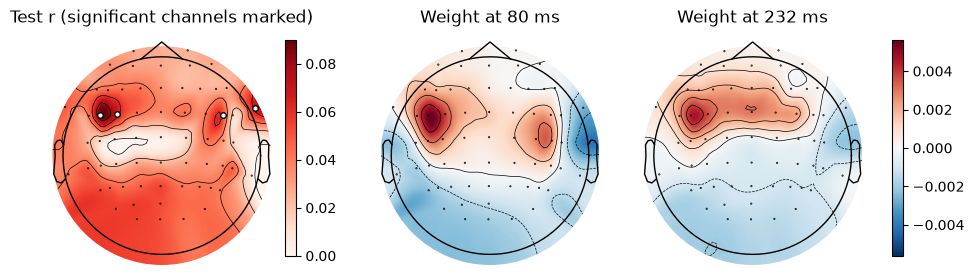

In [8]:
import mne

info = mne.create_info(ch_names, FS, ch_types='eeg')
info.set_montage('standard_1005')

sig = r > thr                                          # channels above the corrected threshold
k80, k232 = np.argmin(np.abs(t_ms - 80)), np.argmin(np.abs(t_ms - 232))
v = np.abs(coef[[k80, k232], :]).max()                # shared symmetric colour scale for the weights

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
im0, _ = mne.viz.plot_topomap(r, info, axes=axs[0], cmap='Reds', mask=sig, show=False)
im1, _ = mne.viz.plot_topomap(coef[k80], info, axes=axs[1], cmap='RdBu_r', vlim=(-v, v), show=False)
im2, _ = mne.viz.plot_topomap(coef[k232], info, axes=axs[2], cmap='RdBu_r', vlim=(-v, v), show=False)
axs[0].set_title('Test r (significant channels marked)')
axs[1].set_title('Weight at 80 ms'); axs[2].set_title('Weight at 232 ms')
fig.colorbar(im0, ax=axs[0], shrink=0.7); fig.colorbar(im2, ax=list(axs[1:]), shrink=0.7)
plt.savefig(os.path.join(FIG, "env_topo.pdf"), bbox_inches="tight")


In [9]:
print(f"FT10 weight at 80 ms: {coef[k80, ch_names.index('FT10')]:.4f}")

FT10 weight at 80 ms: -0.0025
